# GPU-Based Gaussian Blur

This notebook evaluates Gaussian blur using CPU computing with Numba and GPU computing with Numba CUDA on an NVIDIA Tesla T4.

The experiments cover:

- Correctness using a real grayscale image.
- CPU and GPU performance across different image resolutions.
- GPU thread-block configuration.
- GPU memory transfer performance.
- GPU utilization, memory usage, and power monitoring.

A real image is used for visual correctness demonstration. Synthetic images are used for repeatable performance benchmarks.


## 1. GPU Environment and Libraries

The experiments use Google Colab with an NVIDIA Tesla T4 GPU.

Numba CUDA is used to implement the GPU-based Gaussian blur kernel. NumPy and Numba are used for the CPU implementation, while Pandas and Matplotlib are used for result analysis and visualization.

The CUDA environment and GPU availability are verified before executing the experiments.


In [1]:
!pip -q install "numba-cuda[cu13]"

!nvidia-smi

import os
import time
import math
import threading
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numba import cuda, njit
from IPython.display import display

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Numba version:", __import__("numba").__version__)
print("CUDA available:", cuda.is_available())

if not cuda.is_available():
    raise RuntimeError("CUDA GPU is not available. Select a GPU runtime in Colab.")

print("GPU:", cuda.get_current_device().name)

Sat Nov 14 08:09:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Gaussian Filter

Gaussian blur is an image-processing operation used to reduce image noise and fine details.

It works by replacing each pixel with a weighted average of its neighbouring pixels. The weights are determined by a Gaussian distribution, giving greater importance to pixels closer to the centre.

A 5 × 5 Gaussian kernel is used in this experiment. The kernel is normalized so that its elements sum to 1.

The same kernel and boundary-handling method are used in both CPU and GPU implementations to ensure a fair comparison.

In [2]:
GAUSSIAN_KERNEL = np.array([
    [1,  4,  6,  4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1,  4,  6,  4, 1]
], dtype=np.float32) / 256.0

print("Gaussian Kernel:")
print(GAUSSIAN_KERNEL)

print("\nKernel sum:", GAUSSIAN_KERNEL.sum())

Gaussian Kernel:
[[0.00390625 0.015625   0.0234375  0.015625   0.00390625]
 [0.015625   0.0625     0.09375    0.0625     0.015625  ]
 [0.0234375  0.09375    0.140625   0.09375    0.0234375 ]
 [0.015625   0.0625     0.09375    0.0625     0.015625  ]
 [0.00390625 0.015625   0.0234375  0.015625   0.00390625]]

Kernel sum: 1.0


## 3. CPU Implementation

The CPU implementation performs Gaussian convolution using nested loops.

For every pixel, the 5 × 5 neighbourhood is multiplied by the corresponding Gaussian kernel values. The weighted values are summed to obtain the output pixel.

Boundary pixels are handled using edge replication, where pixels outside the image boundaries are assigned the value of the nearest boundary pixel.

In [3]:
@njit
def gaussian_blur_cpu(image, kernel):

    height, width = image.shape
    output = np.zeros((height, width), dtype=np.float32)

    kernel_size = kernel.shape[0]
    radius = kernel_size // 2

    for y in range(height):
        for x in range(width):

            value = 0.0

            for ky in range(kernel_size):
                for kx in range(kernel_size):

                    iy = y + ky - radius
                    ix = x + kx - radius

                    # Edge replication
                    iy = min(max(iy, 0), height - 1)
                    ix = min(max(ix, 0), width - 1)

                    value += image[iy, ix] * kernel[ky, kx]

            output[y, x] = value

    return output

## 4. GPU Implementation Using Numba CUDA

The GPU implementation assigns one CUDA thread to each output pixel.

Each thread calculates the weighted sum of the corresponding 5 × 5 neighbourhood using the Gaussian kernel.

A two-dimensional CUDA grid allows multiple pixels to be processed in parallel.

The GPU implementation uses the same Gaussian kernel and edge-replication boundary handling as the CPU implementation.

In [4]:
@cuda.jit
def gaussian_blur_kernel(image, output, kernel, height, width):

    y, x = cuda.grid(2)

    if y < height and x < width:

        value = 0.0

        for ky in range(5):
            for kx in range(5):

                iy = y + ky - 2
                ix = x + kx - 2

                # Edge replication
                if iy < 0:
                    iy = 0
                elif iy >= height:
                    iy = height - 1

                if ix < 0:
                    ix = 0
                elif ix >= width:
                    ix = width - 1

                value += image[iy, ix] * kernel[ky, kx]

        output[y, x] = value


def gaussian_blur_gpu(image, threads_per_block=(16, 16)):

    image = image.astype(np.float32)

    height, width = image.shape

    threads = threads_per_block

    blocks = (
        (height + threads[0] - 1) // threads[0],
        (width + threads[1] - 1) // threads[1]
    )

    d_image = cuda.to_device(image)

    d_output = cuda.device_array(
        (height, width), dtype=np.float32
    )

    d_kernel = cuda.to_device(GAUSSIAN_KERNEL)

    gaussian_blur_kernel[blocks, threads](
        d_image, d_output, d_kernel, height, width
    )

    cuda.synchronize()

    return d_output.copy_to_host()

## 5. Gaussian Blur on a Real Image

A real grayscale image from the scikit-image sample dataset is used to demonstrate Gaussian blur.

The same image is processed using CPU and GPU implementations.

The outputs are compared numerically and visually to verify that both implementations produce equivalent results.

In [5]:
!pip -q install scikit-image

from skimage import data

# Load the same real grayscale image used in the Sobel notebook
real_image = data.camera()

# CPU processing
cpu_real_blur = gaussian_blur_cpu(
    real_image, GAUSSIAN_KERNEL
)

# GPU processing
gpu_real_blur = gaussian_blur_gpu(real_image)

# Correctness verification
max_difference = np.max(
    np.abs(cpu_real_blur - gpu_real_blur)
)

outputs_match = np.allclose(
    cpu_real_blur,
    gpu_real_blur,
    rtol=1e-5,
    atol=1e-4
)

print("Image shape:", real_image.shape)
print("Maximum absolute difference:", max_difference)
print("CPU and GPU outputs match:", outputs_match)

if not outputs_match:
    raise AssertionError("CPU and GPU Gaussian blur outputs do not match.")

Image shape: (512, 512)
Maximum absolute difference: 0.0
CPU and GPU outputs match: True


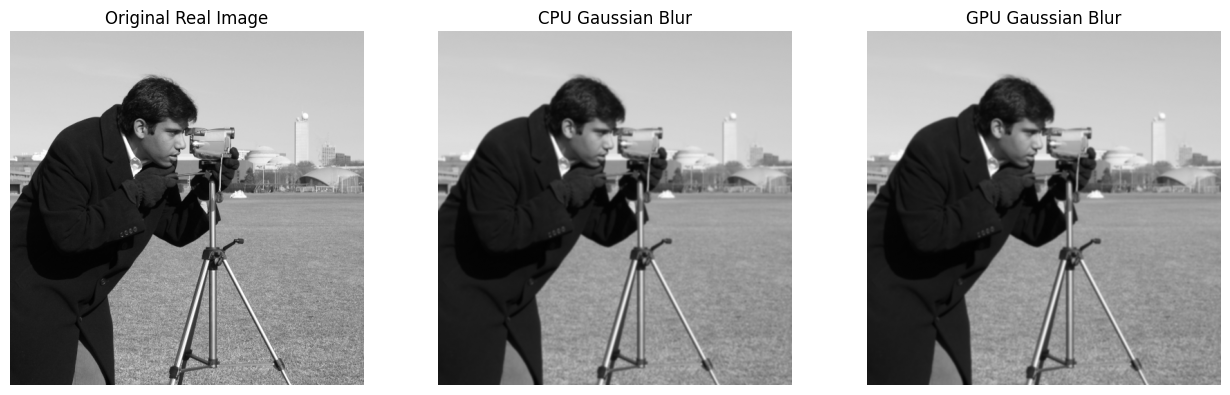

In [6]:
plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(real_image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Real Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cpu_real_blur, cmap="gray", vmin=0, vmax=255)
plt.title("CPU Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gpu_real_blur, cmap="gray", vmin=0, vmax=255)
plt.title("GPU Gaussian Blur")
plt.axis("off")

plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)

plt.savefig(
    "results/figures/gaussian_real_image_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Performance Across Different Image Resolutions

Repeatable synthetic grayscale images are generated at four resolutions:

- 256 × 256
- 512 × 512
- 1024 × 1024
- 2048 × 2048

For each resolution, the notebook measures:

- CPU execution time.
- GPU kernel execution time, excluding data transfers.
- GPU end-to-end execution time, including input transfer, output allocation, kernel execution and output transfer.

The same input image is used for CPU and GPU measurements at each resolution.

Warm-up executions are performed before timing to reduce the effect of CPU compilation, CUDA initialization and kernel compilation overhead.

In [7]:
def benchmark_gaussian_blur(image, repetitions=20):

    height, width = image.shape

    image_float = image.astype(np.float32)

    threads = (16, 16)

    blocks = (
        (height + threads[0] - 1) // threads[0],
        (width + threads[1] - 1) // threads[1]
    )

    # CPU warm-up
    gaussian_blur_cpu(image_float, GAUSSIAN_KERNEL)

    # GPU warm-up
    gaussian_blur_gpu(image_float, threads)
    cuda.synchronize()

    # CPU timing
    cpu_times = []

    for _ in range(repetitions):

        start = time.perf_counter()

        cpu_result = gaussian_blur_cpu(
            image_float, GAUSSIAN_KERNEL
        )

        cpu_times.append(time.perf_counter() - start)

    cpu_avg_ms = np.mean(cpu_times) * 1000

    # GPU setup for kernel-only timing
    d_input = cuda.to_device(image_float)

    d_output = cuda.device_array(
        (height, width), dtype=np.float32
    )

    d_kernel = cuda.to_device(GAUSSIAN_KERNEL)

    # GPU kernel warm-up
    gaussian_blur_kernel[blocks, threads](
        d_input, d_output, d_kernel, height, width
    )
    cuda.synchronize()

    # GPU kernel timing
    start_event = cuda.event()
    end_event = cuda.event()

    start_event.record()

    for _ in range(50):

        gaussian_blur_kernel[blocks, threads](
            d_input, d_output, d_kernel, height, width
        )

    end_event.record()
    end_event.synchronize()

    gpu_kernel_avg_ms = (
        cuda.event_elapsed_time(start_event, end_event) / 50
    )

    # GPU end-to-end timing
    total_times = []

    # Warm-up for complete end-to-end execution
    d_warm_input = cuda.to_device(image_float)

    d_warm_output = cuda.device_array(
        (height, width), dtype=np.float32
    )

    gaussian_blur_kernel[blocks, threads](
        d_warm_input, d_warm_output,
        d_kernel, height, width
    )

    d_warm_output.copy_to_host()
    cuda.synchronize()

    for _ in range(10):

        cuda.synchronize()
        start = time.perf_counter()

        d_in = cuda.to_device(image_float)

        d_out = cuda.device_array(
            (height, width), dtype=np.float32
        )

        gaussian_blur_kernel[blocks, threads](
            d_in, d_out, d_kernel, height, width
        )

        gpu_result = d_out.copy_to_host()

        cuda.synchronize()

        total_times.append(time.perf_counter() - start)

    gpu_total_avg_ms = np.mean(total_times) * 1000

    # Correctness verification
    max_difference = np.max(
        np.abs(cpu_result - gpu_result)
    )

    outputs_match = np.allclose(
        cpu_result,
        gpu_result,
        rtol=1e-5,
        atol=1e-4
    )

    return {
        "Resolution": f"{height}x{width}",
        "CPU (ms)": cpu_avg_ms,
        "GPU Kernel (ms)": gpu_kernel_avg_ms,
        "GPU End-to-End (ms)": gpu_total_avg_ms,
        "Kernel Speedup": cpu_avg_ms / gpu_kernel_avg_ms,
        "End-to-End Speedup": cpu_avg_ms / gpu_total_avg_ms,
        "Maximum Difference": max_difference,
        "Outputs Match": outputs_match
    }

resolutions = [256, 512, 1024, 2048]

results = []
correctness_results = []

for size in resolutions:

    print(f"Running {size} x {size} ...")

    rng = np.random.default_rng(42)

    test_image = rng.integers(
        0, 256,
        size=(size, size),
        dtype=np.uint8
    ).astype(np.float32)

    result = benchmark_gaussian_blur(
        test_image, repetitions=20
    )

    results.append(result)

    correctness_results.append({
        "Resolution": result["Resolution"],
        "Outputs Match": result["Outputs Match"],
        "Maximum Difference": result["Maximum Difference"]
    })

    print(
        f"Completed: {size}x{size} | "
        f"Correctness: {result['Outputs Match']}"
    )

results_df = pd.DataFrame(results)

correctness_df = pd.DataFrame(correctness_results)

print("Performance comparison:")
display(
    results_df[
        [
            "Resolution",
            "CPU (ms)",
            "GPU Kernel (ms)",
            "GPU End-to-End (ms)",
            "Kernel Speedup",
            "End-to-End Speedup"
        ]
    ].round(4)
)

print("Correctness verification:")
display(correctness_df.round(6))

Running 256 x 256 ...
Completed: 256x256 | Correctness: True
Running 512 x 512 ...
Completed: 512x512 | Correctness: True
Running 1024 x 1024 ...
Completed: 1024x1024 | Correctness: True
Running 2048 x 2048 ...
Completed: 2048x2048 | Correctness: True
Performance comparison:


,Resolution,CPU (ms),GPU Kernel (ms),GPU End-to-End (ms),Kernel Speedup,End-to-End Speedup
0,256x256,9.5561,0.1737,2.8541,55.0165,3.3482
1,512x512,57.0255,0.3454,2.4261,165.0910,23.5049
2,1024x1024,195.7536,1.3303,6.0277,147.1521,32.4758
3,2048x2048,274.2748,4.5730,10.4879,59.9765,26.1514


Correctness verification:


,Resolution,Outputs Match,Maximum Difference
0,256x256,True,0.0
1,512x512,True,0.0
2,1024x1024,True,0.0
3,2048x2048,True,0.0


## 7. GPU Memory Transfer Performance

GPU applications require data to be transferred between CPU memory and GPU memory.

This experiment measures two transfer operations separately:

- Host-to-Device (H2D): Transfer of the input image from CPU memory to GPU memory.
- Device-to-Host (D2H): Transfer of the processed output from GPU memory back to CPU memory.

Both measurements are performed using a 2048 × 2048 image.

The average transfer time is calculated over multiple runs.

In [8]:
# Prepare a repeatable 2048 x 2048 image
rng = np.random.default_rng(42)

transfer_image = rng.integers(
    0, 256,
    size=(2048, 2048),
    dtype=np.uint8
).astype(np.float32)

transfer_runs = 100

# Allocate GPU memory before measuring transfers
d_transfer_input = cuda.device_array(
    transfer_image.shape,
    dtype=np.float32
)

d_transfer_output = cuda.device_array(
    transfer_image.shape,
    dtype=np.float32
)

# Initialize output memory before D2H measurement
d_transfer_output.copy_to_device(transfer_image)

# Warm-up transfers
d_transfer_input.copy_to_device(transfer_image)
d_transfer_output.copy_to_host()
cuda.synchronize()

# Measure Host-to-Device transfer
h2d_times = []

for _ in range(transfer_runs):

    cuda.synchronize()
    start = time.perf_counter()

    d_transfer_input.copy_to_device(transfer_image)

    cuda.synchronize()

    h2d_times.append(
        time.perf_counter() - start
    )

h2d_avg_ms = np.mean(h2d_times) * 1000

# Measure Device-to-Host transfer
d2h_times = []

for _ in range(transfer_runs):

    cuda.synchronize()
    start = time.perf_counter()

    output_cpu = d_transfer_output.copy_to_host()

    cuda.synchronize()

    d2h_times.append(
        time.perf_counter() - start
    )

d2h_avg_ms = np.mean(d2h_times) * 1000

print("GPU Memory Transfer Results")
print("---------------------------")
print("Image resolution: 2048 x 2048")
print("Average H2D transfer time:", round(h2d_avg_ms, 5), "ms")
print("Average D2H transfer time:", round(d2h_avg_ms, 5), "ms")

GPU Memory Transfer Results
---------------------------
Image resolution: 2048 x 2048
Average H2D transfer time: 3.51409 ms
Average D2H transfer time: 3.91491 ms


## 8. Thread-Block Configuration Comparison

The GPU kernel is evaluated using three thread-block configurations:

- 8 × 8 threads
- 16 × 16 threads
- 32 × 32 threads

The same 512 × 512 real image is used for all configurations.

The experiment compares GPU kernel execution time and verifies the correctness of each configuration against the CPU output.

In [9]:
thread_configs = [(8, 8), (16, 16), (32, 32)]

block_results = []

real_image_float = real_image.astype(np.float32)

cpu_block_output = gaussian_blur_cpu(
    real_image_float, GAUSSIAN_KERNEL
)

d_real_image = cuda.to_device(real_image_float)

d_gaussian_kernel = cuda.to_device(GAUSSIAN_KERNEL)

for threads in thread_configs:

    height, width = real_image.shape

    blocks = (
        (height + threads[0] - 1) // threads[0],
        (width + threads[1] - 1) // threads[1]
    )

    d_output = cuda.device_array(
        real_image.shape,
        dtype=np.float32
    )

    # Warm-up
    gaussian_blur_kernel[blocks, threads](
        d_real_image,
        d_output,
        d_gaussian_kernel,
        height,
        width
    )

    cuda.synchronize()

    start_event = cuda.event()
    end_event = cuda.event()

    start_event.record()

    for _ in range(100):

        gaussian_blur_kernel[blocks, threads](
            d_real_image,
            d_output,
            d_gaussian_kernel,
            height,
            width
        )

    end_event.record()
    end_event.synchronize()

    avg_time_ms = (
        cuda.event_elapsed_time(start_event, end_event) / 100
    )

    output = d_output.copy_to_host()

    outputs_match = np.allclose(
        cpu_block_output,
        output,
        rtol=1e-5,
        atol=1e-4
    )

    block_results.append({
        "Threads per Block": f"{threads[0]}x{threads[1]}",
        "Total Threads": threads[0] * threads[1],
        "GPU Kernel Time (ms)": avg_time_ms,
        "Outputs Match": outputs_match,
        "Maximum Difference": np.max(
            np.abs(cpu_block_output - output)
        )
    })

block_df = pd.DataFrame(block_results)

display(block_df.round(5))

,Threads per Block,Total Threads,GPU Kernel Time (ms),Outputs Match,Maximum Difference
0,8x8,64,0.13254,True,0.0
1,16x16,256,0.13524,True,0.0
2,32x32,1024,0.26464,True,0.0


## 9. Performance Graphs

The following graphs summarize the resolution benchmark:

- CPU versus GPU kernel execution time.
- CPU versus GPU end-to-end execution time.
- GPU kernel and end-to-end speedup across image resolutions.

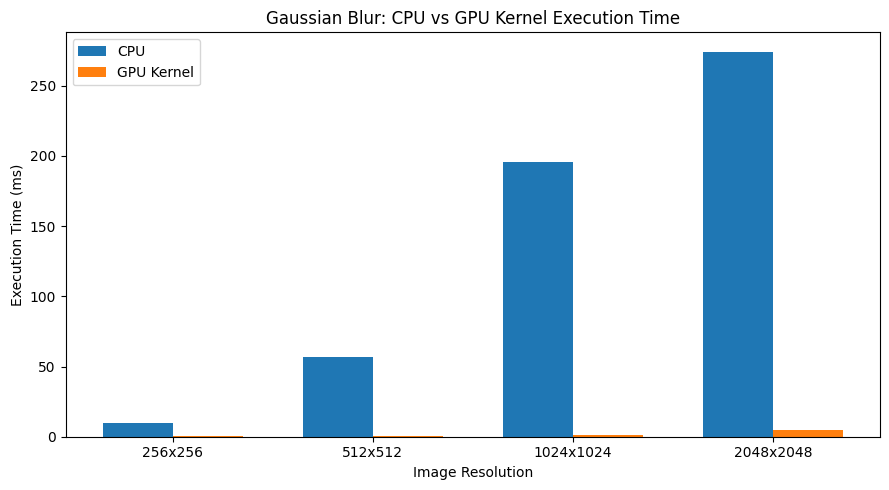

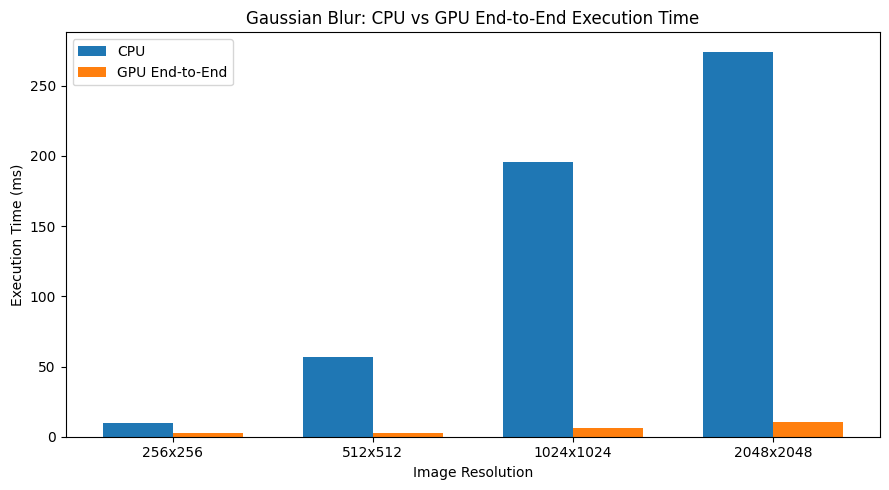

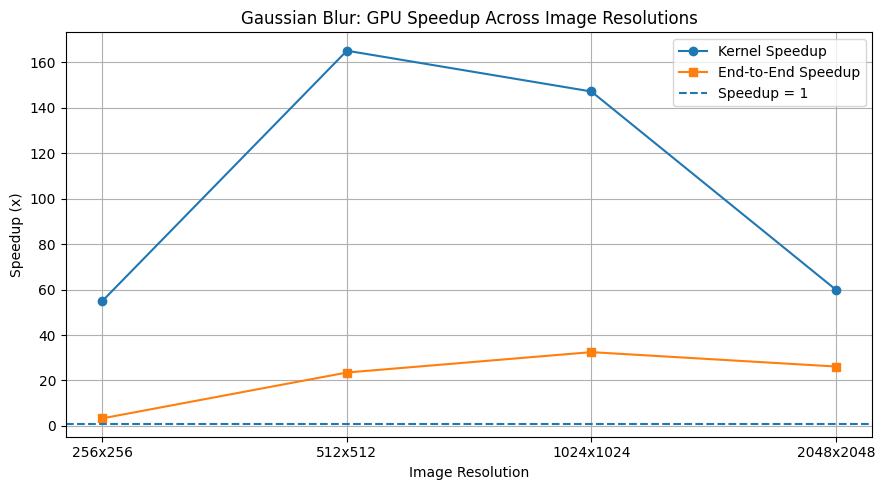

Performance graphs saved in results/figures/


In [10]:
os.makedirs("results/figures", exist_ok=True)

x = np.arange(len(results_df))
labels = results_df["Resolution"]
bar_width = 0.35

# CPU vs GPU kernel execution time
plt.figure(figsize=(9, 5))

plt.bar(
    x - bar_width / 2,
    results_df["CPU (ms)"],
    bar_width,
    label="CPU"
)

plt.bar(
    x + bar_width / 2,
    results_df["GPU Kernel (ms)"],
    bar_width,
    label="GPU Kernel"
)

plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("Gaussian Blur: CPU vs GPU Kernel Execution Time")
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()

plt.savefig(
    "results/figures/gaussian_cpu_vs_gpu_kernel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# CPU vs GPU end-to-end execution time
plt.figure(figsize=(9, 5))

plt.bar(
    x - bar_width / 2,
    results_df["CPU (ms)"],
    bar_width,
    label="CPU"
)

plt.bar(
    x + bar_width / 2,
    results_df["GPU End-to-End (ms)"],
    bar_width,
    label="GPU End-to-End"
)

plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("Gaussian Blur: CPU vs GPU End-to-End Execution Time")
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()

plt.savefig(
    "results/figures/gaussian_cpu_vs_gpu_end_to_end.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Kernel and end-to-end speedup
plt.figure(figsize=(9, 5))

plt.plot(
    labels,
    results_df["Kernel Speedup"],
    marker="o",
    label="Kernel Speedup"
)

plt.plot(
    labels,
    results_df["End-to-End Speedup"],
    marker="s",
    label="End-to-End Speedup"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Speedup = 1"
)

plt.xlabel("Image Resolution")
plt.ylabel("Speedup (x)")
plt.title("Gaussian Blur: GPU Speedup Across Image Resolutions")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "results/figures/gaussian_speedup_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance graphs saved in results/figures/")

## 10. GPU Resource Utilization and Memory Monitoring

The GPU is monitored while the 2048 × 2048 Gaussian blur workload is executed repeatedly.

Measurements include:

- GPU utilization.
- GPU memory usage.
- GPU power consumption.

The measurements are sampled periodically using NVIDIA System Management Interface (nvidia-smi).

A warm-up execution is performed before monitoring begins.

In [11]:
# Generate repeatable 2048 x 2048 input
monitor_image = np.random.default_rng(42).integers(
    0, 256,
    size=(2048, 2048),
    dtype=np.uint8
)

# Warm-up before monitoring
gaussian_blur_gpu(monitor_image)
cuda.synchronize()

measurements = []
stop_monitoring = threading.Event()


def monitor_gpu():

    while not stop_monitoring.is_set():

        try:

            result = subprocess.run(
                [
                    "nvidia-smi",
                    "--query-gpu=utilization.gpu,memory.used,memory.total,power.draw",
                    "--format=csv,noheader,nounits"
                ],
                capture_output=True,
                text=True,
                timeout=2
            )

            if result.returncode == 0 and result.stdout.strip():

                values = [
                    value.strip()
                    for value in result.stdout.strip().split(",")
                ]

                measurements.append({
                    "GPU Utilization (%)": float(values[0]),
                    "Memory Used (MB)": float(values[1]),
                    "Total Memory (MB)": float(values[2]),
                    "Power Usage (W)": (
                        float(values[3])
                        if values[3] not in ["N/A", "[N/A]"]
                        else np.nan
                    )
                })

        except Exception:
            pass

        stop_monitoring.wait(0.1)


monitor_thread = threading.Thread(target=monitor_gpu)
monitor_thread.start()

start_time = time.perf_counter()

for _ in range(100):
    monitor_output = gaussian_blur_gpu(monitor_image)

cuda.synchronize()

workload_time = time.perf_counter() - start_time

stop_monitoring.set()
monitor_thread.join()

df_active = pd.DataFrame(measurements)

print("Image resolution:", monitor_image.shape)
print("Number of Gaussian blur executions:", 100)
print("Workload execution time:", round(workload_time, 3), "seconds")
print("Number of monitoring samples:", len(df_active))

if df_active.empty:
    print("No GPU monitoring samples were collected.")
else:
    display(df_active.describe().round(2))

Image resolution: (2048, 2048)
Number of Gaussian blur executions: 100
Workload execution time: 1.72 seconds
Number of monitoring samples: 11


,GPU Utilization (%),Memory Used (MB),Total Memory (MB),Power Usage (W)
count,11.00,11.00,11.0,11.00
mean,38.55,209.36,15360.0,31.94
std,12.33,35.12,0.0,1.99
min,3.00,157.00,15360.0,28.04
25%,40.00,181.00,15360.0,30.90
50%,41.00,205.00,15360.0,31.77
75%,43.00,229.00,15360.0,33.10
max,51.00,269.00,15360.0,35.21


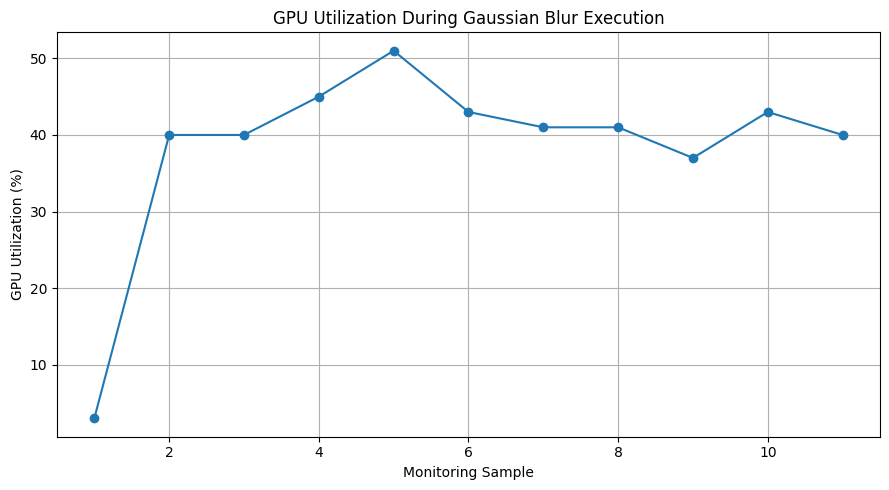

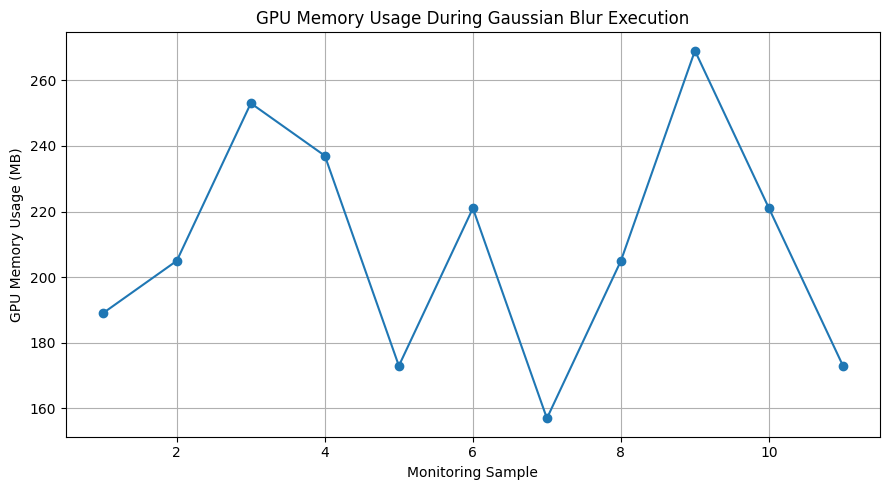

GPU resource monitoring graphs saved successfully.


In [12]:
if not df_active.empty:

    # GPU utilization
    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(df_active) + 1),
        df_active["GPU Utilization (%)"],
        marker="o"
    )

    plt.xlabel("Monitoring Sample")
    plt.ylabel("GPU Utilization (%)")
    plt.title("GPU Utilization During Gaussian Blur Execution")
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        "results/figures/gaussian_gpu_utilization_monitoring.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    # GPU memory usage
    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(df_active) + 1),
        df_active["Memory Used (MB)"],
        marker="o"
    )

    plt.xlabel("Monitoring Sample")
    plt.ylabel("GPU Memory Usage (MB)")
    plt.title("GPU Memory Usage During Gaussian Blur Execution")
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        "results/figures/gaussian_gpu_memory_monitoring.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("GPU resource monitoring graphs saved successfully.")

else:
    print("No resource graphs generated because no samples were collected.")

## 11. Results and Discussion

### 11.1 CPU and GPU Performance Comparison

Gaussian blur was evaluated at four image resolutions: 256×256, 512×512, 1024×1024, and 2048×2048.

The CPU implementation was compared with the GPU implementation using two measurements:

- **GPU Kernel Time:** Time taken by the GPU to execute the Gaussian blur kernel, excluding memory transfers.
- **GPU End-to-End Time:** Total GPU execution time, including host-to-device transfer, output allocation, kernel execution, and device-to-host transfer.

All four resolutions produced matching CPU and GPU outputs, with a maximum absolute difference of 0.0.

The benchmark results show that:

- GPU kernel execution was faster than CPU execution at all tested resolutions.
- Kernel speedup ranged from approximately 55.02× to 165.09×.
- End-to-end speedup ranged from approximately 3.35× to 32.48×.
- The highest kernel speedup was observed at 512×512 resolution.
- The highest end-to-end speedup was observed at 1024×1024 resolution.

These results demonstrate that GPU acceleration provides substantial performance benefits for Gaussian blur. However, speedup does not increase uniformly with image resolution because execution time is also influenced by memory transfers, allocation overhead, and runtime conditions.

### 11.2 GPU Memory Transfer Performance

For a 2048×2048 image, the average memory transfer times were:

- Host-to-Device (H2D): 3.51409 ms
- Device-to-Host (D2H): 3.91491 ms

These measurements demonstrate that data movement contributes to overall GPU execution time. Therefore, kernel execution time alone does not represent the complete performance of a GPU-based image-processing application.

### 11.3 Thread-Block Configuration Analysis

The Gaussian blur kernel was evaluated using three thread-block configurations: 8×8, 16×16, and 32×32.

The measured GPU kernel times were:

- 8×8: 0.13254 ms
- 16×16: 0.13524 ms
- 32×32: 0.26464 ms

The 8×8 configuration achieved the lowest execution time, closely followed by 16×16. The 32×32 configuration was slower in this experiment.

This demonstrates that thread-block configuration can influence GPU performance. A larger block size does not necessarily provide better performance for every workload.

### 11.4 GPU Resource Utilization Analysis

Resource utilization was monitored while executing the Gaussian blur workload 100 times on the NVIDIA Tesla T4 GPU using a 2048×2048 image.

The monitoring results were:

- Average GPU utilization: 38.55%
- Average GPU memory usage: 209.36 MB
- Total GPU memory: 15360 MB
- Average power usage: 31.94 W
- Workload execution time: 1.72 seconds
- Number of monitoring samples: 11

The GPU utilization indicates that the workload actively used the GPU during execution. The average memory consumption was relatively small compared with the available GPU memory.

These results provide an indication of the computational and memory requirements of the Gaussian blur workload on the cloud GPU environment.

### 11.5 Overall Observations

The experiments demonstrate that:

1. GPU acceleration provides substantial performance improvements over CPU execution for Gaussian blur.
2. The highest measured kernel speedup was 165.09×, while the highest end-to-end speedup was 32.48×.
3. Memory transfers contribute to overall execution time and should be considered when evaluating GPU performance.
4. Thread-block configuration affects execution performance, with 8×8 providing the lowest measured kernel time in this experiment.
5. GPU resource utilization and memory consumption provide additional insight into the computational requirements of the workload.

Overall, the results demonstrate the effectiveness of GPU acceleration for computationally intensive image-processing operations.

## 12. Experimental Limitations

The experiments were conducted using Google Colab with an NVIDIA Tesla T4 GPU. The following limitations should be considered when interpreting the results:

1. **Cloud Environment Variability:** GPU performance and resource availability may vary depending on the shared cloud environment and other running workloads.
2. **Benchmark Variability:** Execution times may fluctuate due to GPU scheduling, runtime conditions, clock frequency, and measurement overhead.
3. **Hardware Availability:** The experiments were conducted on a single NVIDIA Tesla T4 GPU. Performance may differ on other GPU architectures.
4. **Limited Workload Configurations:** Only four image resolutions and three thread-block configurations were evaluated.
5. **Resource Monitoring:** GPU utilization and power measurements were collected periodically during execution. Therefore, they represent sampled observations rather than continuous measurements.

## 13. Conclusion

This experiment evaluated the performance of CPU-based and GPU-based Gaussian blur implementations using Python, Numba CUDA, and an NVIDIA Tesla T4 GPU available through Google Colab.

The GPU implementation achieved faster execution than the CPU implementation across all four tested image resolutions. The maximum measured kernel speedup was approximately 165.09× at 512×512 resolution, while the maximum end-to-end speedup was approximately 32.48× at 1024×1024 resolution.

The experiments also examined GPU memory transfer overhead, thread-block configurations, and resource utilization. The results showed that memory transfers contribute to total execution time and that thread-block configuration can influence kernel performance. The 8×8 configuration provided the lowest measured kernel execution time among the tested configurations.

Overall, the experiment demonstrates the benefits of GPU acceleration for image-processing workloads and highlights the importance of considering execution time, memory transfer overhead, resource utilization, and workload scalability when evaluating cloud-based GPU applications.